# PLB Performance Analysis Notebook

This notebook analyzes database performance metrics using the priority load balancer, including:
- **Latency Metrics** (e.g., Average Latency, 95th Percentile Latency).
- **Throughput and Goodput**.

Each plot visualizes:
- **Total Clients (Terminals)** on the outer X-axis.
- **Premium:Freemium Ratios** on the inner X-axis.

**Load Balncer Information:**

- 2 postgres replicas for premium users, each with a threshold of 5
- 3 postgres replicas for freemium users each with a threshold of 7

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker

# Load the CSV
df = pd.read_csv("summary_results_new.csv")


In [2]:
# Combine Premium and Freemium into "Terminal Classes Weights"
df["Terminal Classes Weights"] = df.iloc[:, 5].astype(str) + "," + df.iloc[:, 6].astype(str)

# Verify the result
print("Terminal Classes Weights column:")
print(df[["Terminal Classes Weights"]].head())


Terminal Classes Weights column:
  Terminal Classes Weights
1                    10,40
2                    10,40
3                    10,40
4                    10,40
5                    10,40


In [3]:
# Create Clients_Label: "Total Clients (Premium:Freemium)"
def format_clients(row):
    weights = list(map(int, row["Terminal Classes Weights"].split(',')))  # Split Premium and Freemium
    total_clients = sum(weights)  # Total clients = Premium + Freemium
    return f"{total_clients} ({weights[0]}:{weights[1]})"  # Format: Total (Premium:Freemium)

# Apply the function to create the Clients_Label column
df["Clients_Label"] = df.apply(format_clients, axis=1)

# Verify the result
print("Clients_Label column created")
print(df[["Terminal Classes Weights", "Clients_Label"]].head())


Clients_Label column created
  Terminal Classes Weights Clients_Label
1                    10,40    50 (10:40)
2                    10,40    50 (10:40)
3                    10,40    50 (10:40)
4                    10,40    50 (10:40)
5                    10,40    50 (10:40)


In [4]:
# Convert latency metrics to milliseconds
latency_columns = [
    "Average Latency",
    "95th Percentile Latency",
    "Maximum Latency",
    "Median Latency",
    "Minimum Latency",
    "25th Percentile Latency",
    "90th Percentile Latency",
    "99th Percentile Latency",
    "75th Percentile Latency"
]

# Divide all latency metrics by 1,000 to convert to milliseconds
df[latency_columns] = df[latency_columns].apply(lambda x: x / 1000)

print("Latency metrics converted to milliseconds")


Latency metrics converted to milliseconds


In [5]:
# Extract the total number of clients from Clients_Label
def extract_total_clients(label):
    return int(label.split(" ")[0])  # Extract the number before the '('
def extract_premium(label):
    # Example label: '50 (15:35)' -> Extract 15
    return int(label.split("(")[1].split(":")[0])
    
df["Total Clients"] = df["Clients_Label"].apply(extract_total_clients)
df["Premium Clients"] = df["Clients_Label"].apply(extract_premium)

# Sort by Total Clients
df = df.sort_values(["Premium Clients", "Total Clients"]).reset_index(drop=True)

print("DataFrame sorted by Total Clients")
print(df[["Clients_Label", "Total Clients"]].head())


DataFrame sorted by Total Clients
  Clients_Label  Total Clients
0    50 (10:40)             50
1    50 (10:40)             50
2    50 (10:40)             50
3    50 (10:40)             50
4    50 (10:40)             50


In [6]:
def plot_grouped_bar_chart(df, metric, title, ylabel, output_name=None):
    """
    Function to plot grouped bar chart for a specific metric, with the same color for the same total number of terminals.
    """
    # Sort the DataFrame by Total Clients and Clients_Label
    df = df.sort_values(["Total Clients", "Clients_Label"]).reset_index(drop=True)

    # Create a color map for total clients
    unique_clients = sorted(df["Total Clients"].unique())  # Get sorted unique total clients
    color_map = {client: f"C{i}" for i, client in enumerate(unique_clients)}  # Assign a unique color for each

    fig, ax = plt.subplots(figsize=(12, 6))

    # Create positions for bars
    bar_width = 0.5
    x_positions = np.arange(len(df))  # One position per row in the DataFrame

    # Plot bars with colors based on Total Clients
    ax.bar(
        x_positions,
        df[metric],
        width=bar_width,
        color=[color_map[client] for client in df["Total Clients"]],  # Color by Total Clients
        label="Total Clients"
    )

    # Add X-axis labels for Premium:Freemium combinations
    ax.set_xticks(x_positions)
    ax.set_xticklabels(df["Clients_Label"], rotation=45, ha='right')

    # Customize the plot
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y')

    # Format Y-axis labels as integers
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

    # Add a legend for colors
    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[client]) for client in unique_clients]
    labels = [f"Total Clients: {client}" for client in unique_clients]
    ax.legend(handles, labels, title="Total Clients", bbox_to_anchor=(1.05, 1), loc='upper left')

    # Show the plot
    plt.tight_layout()
    plt.show()

In [7]:
# Extract per-priority metrics
df["Premium Throughput"] = df["premium_Throughput"]
df["Premium Goodput"] = df["premium_Goodput"]
df["Premium Avg Latency"] = df["premium_LatencyStats"].str.extract(r"avg=(\d+)")[0].astype(float)

df["Freemium Throughput"] = df["freemium_Throughput"]
df["Freemium Goodput"] = df["freemium_Goodput"]
df["Freemium Avg Latency"] = df["freemium_LatencyStats"].str.extract(r"avg=(\d+)")[0].astype(float) 

print("Extracted per-priority metrics!")

Extracted per-priority metrics!


In [8]:
def plot_per_priority_grouped_bar_chart(df, metric_premium, metric_freemium, title, ylabel, output_name=None):
    """
    Plot a grouped bar chart for premium vs freemium metrics for each Total Clients configuration.
    """
    df = df.sort_values(["Total Clients", "Clients_Label"]).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(12, 6))
    bar_width = 0.4
    x_positions = np.arange(len(df))

    # Plot Premium bars
    ax.bar(x_positions - bar_width/2, df[metric_premium], width=bar_width, label="Premium", color="tab:blue")

    # Plot Freemium bars
    ax.bar(x_positions + bar_width/2, df[metric_freemium], width=bar_width, label="Freemium", color="tab:orange")

    # X-axis labels
    ax.set_xticks(x_positions)
    ax.set_xticklabels(df["Clients_Label"], rotation=45, ha='right')

    # Labels and title
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

    plt.tight_layout()
    plt.show()


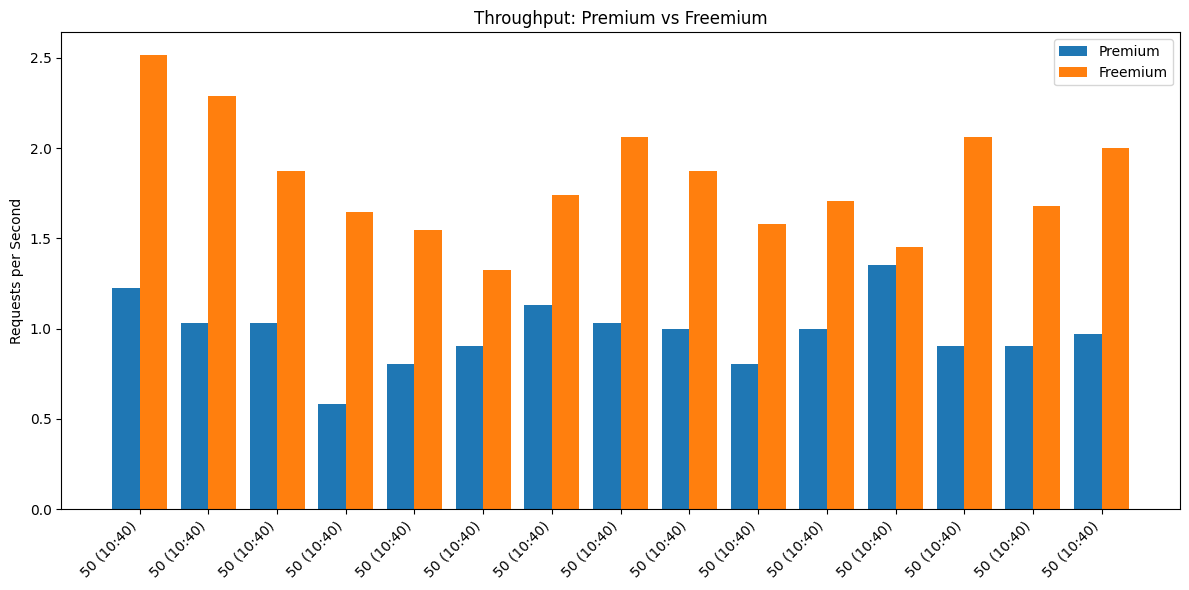

In [9]:
# Plot per-priority metrics

plot_per_priority_grouped_bar_chart(df, 
    metric_premium="Premium Throughput", 
    metric_freemium="Freemium Throughput", 
    title="Throughput: Premium vs Freemium", 
    ylabel="Requests per Second", 
    output_name="throughput_comparison")


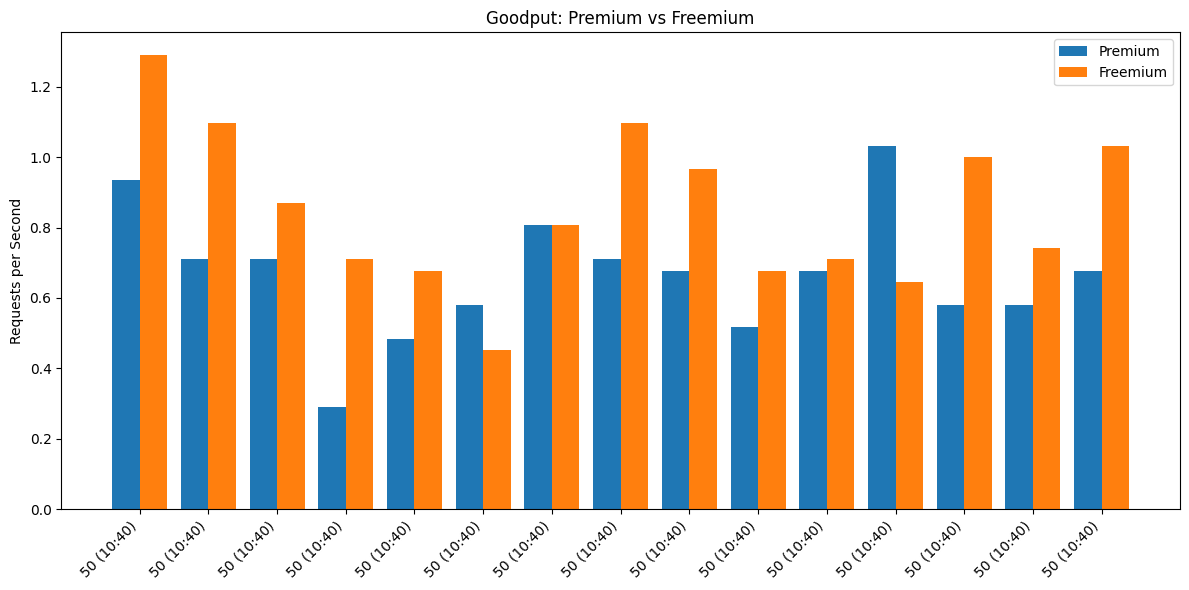

In [10]:
plot_per_priority_grouped_bar_chart(df, 
    metric_premium="Premium Goodput", 
    metric_freemium="Freemium Goodput", 
    title="Goodput: Premium vs Freemium", 
    ylabel="Requests per Second", 
    output_name="goodput_comparison")

In [11]:
# Extract per-priority metrics
df["Premium Per Terminal Throughput"] = df["premium_PerTerminalThroughput"]
df["Premium Per Terminal Goodput"] = df["premium_PerTerminalGoodput"]
df["Premium Avg Latency"] = df["premium_LatencyStats"].str.extract(r"avg=(\d+)")[0].astype(float)

df["Freemium Per Terminal Throughput"] = df["freemium_PerTerminalThroughput"]
df["Freemium Per Terminal Goodput"] = df["freemium_PerTerminalGoodput"]
df["Freemium Avg Latency"] = df["freemium_LatencyStats"].str.extract(r"avg=(\d+)")[0].astype(float) 

print("Extracted per-priority_per-terminal metrics!")

Extracted per-priority_per-terminal metrics!


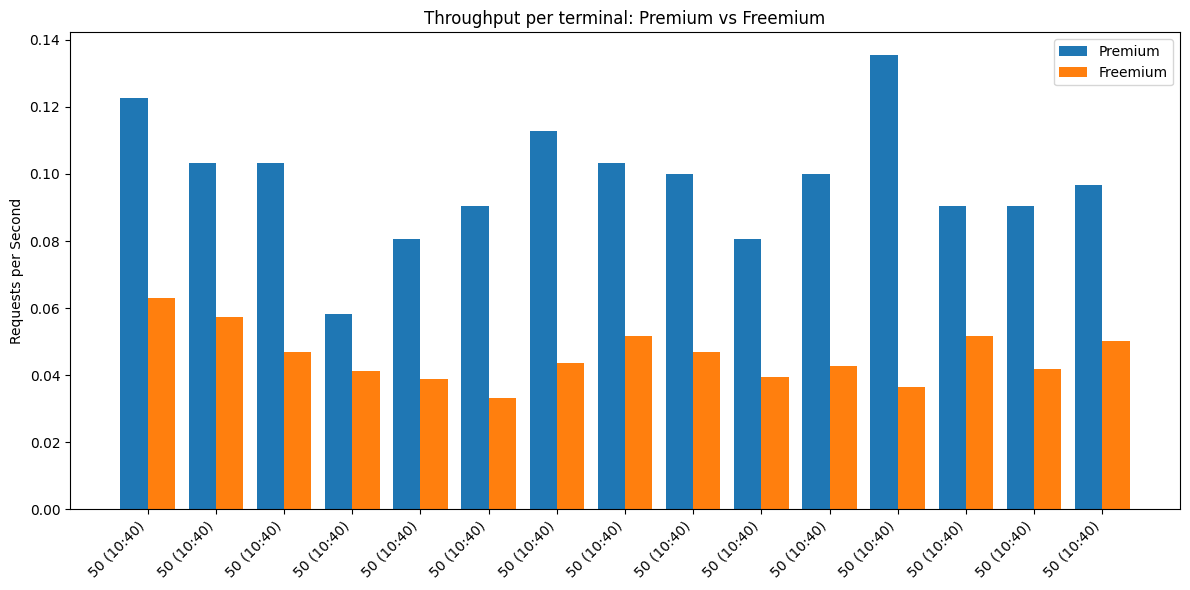

In [12]:
plot_per_priority_grouped_bar_chart(df, 
    metric_premium="Premium Per Terminal Throughput", 
    metric_freemium="Freemium Per Terminal Throughput", 
    title="Throughput per terminal: Premium vs Freemium", 
    ylabel="Requests per Second", 
    output_name="throughput_per_terminal_comparison")


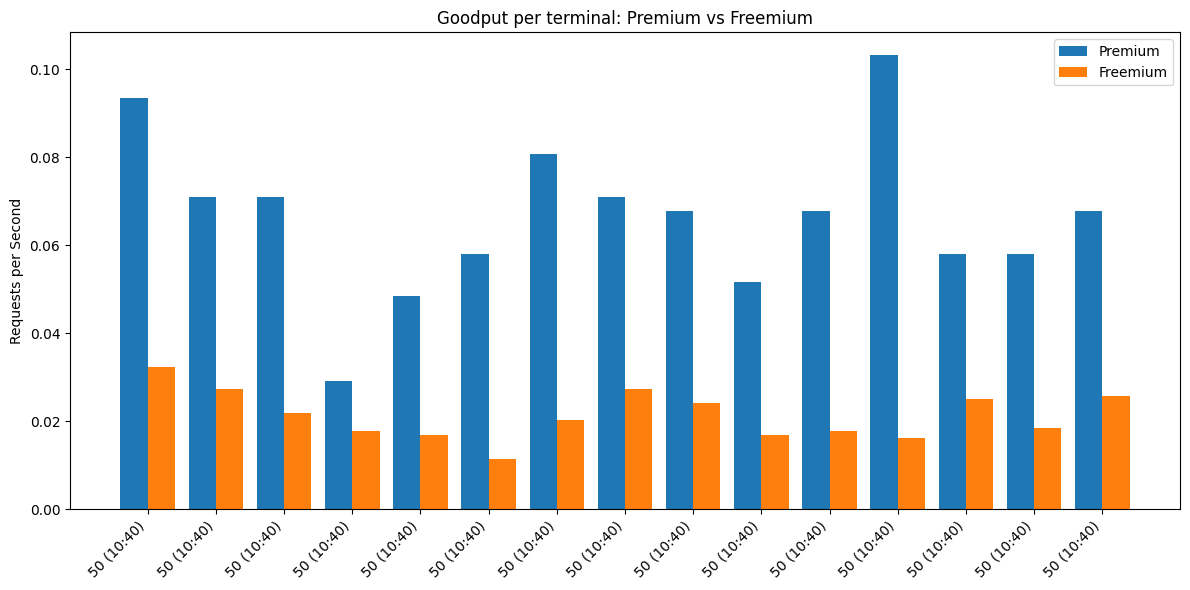

In [13]:
plot_per_priority_grouped_bar_chart(df, 
    metric_premium="Premium Per Terminal Goodput", 
    metric_freemium="Freemium Per Terminal Goodput", 
    title="Goodput per terminal: Premium vs Freemium", 
    ylabel="Requests per Second", 
    output_name="goodput_per_terminal_comparison")

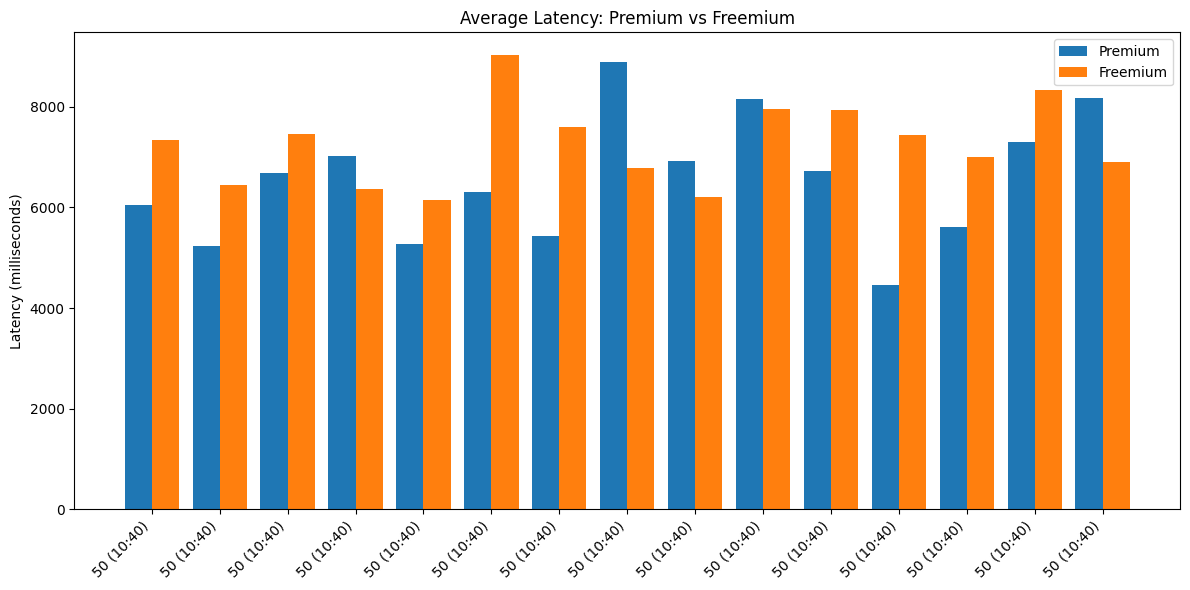

In [14]:
plot_per_priority_grouped_bar_chart(df, 
    metric_premium="Premium Avg Latency", 
    metric_freemium="Freemium Avg Latency", 
    title="Average Latency: Premium vs Freemium", 
    ylabel="Latency (milliseconds)", 
    output_name="avg_latency_comparison")


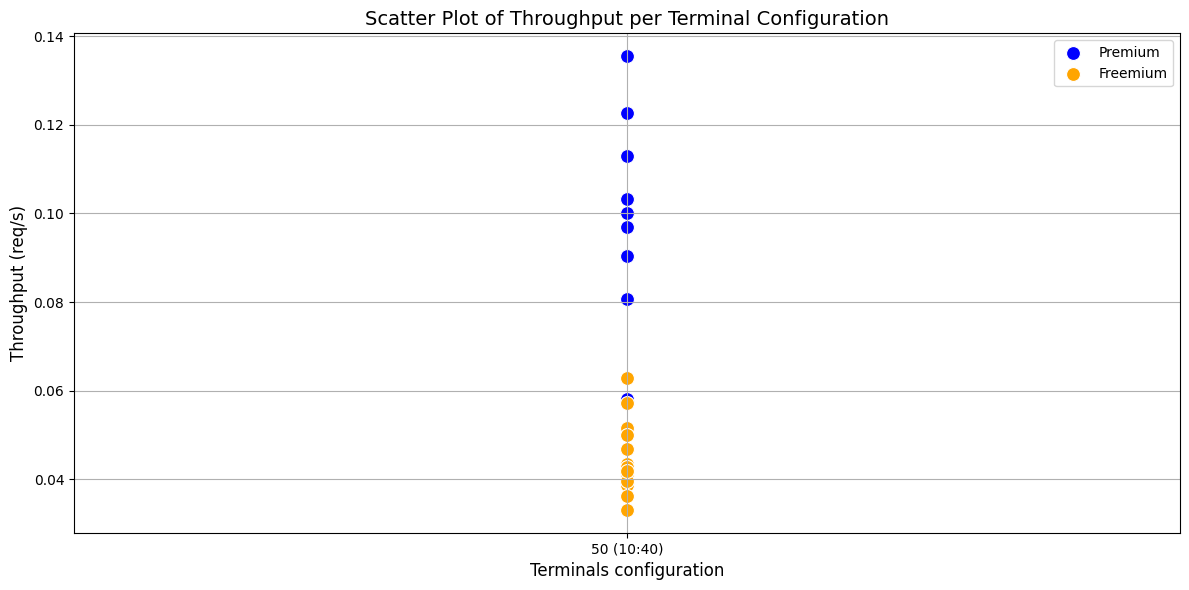

In [15]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Clients_Label', y='Premium Per Terminal Throughput', data=df, label='Premium', color='blue', s=100)
sns.scatterplot(x='Clients_Label', y='Freemium Per Terminal Throughput', data=df, label='Freemium', color='orange', s=100)
plt.xlabel('Terminals configuration', fontsize=12)
plt.ylabel('Throughput (req/s)', fontsize=12)
plt.title('Scatter Plot of Throughput per Terminal Configuration', fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

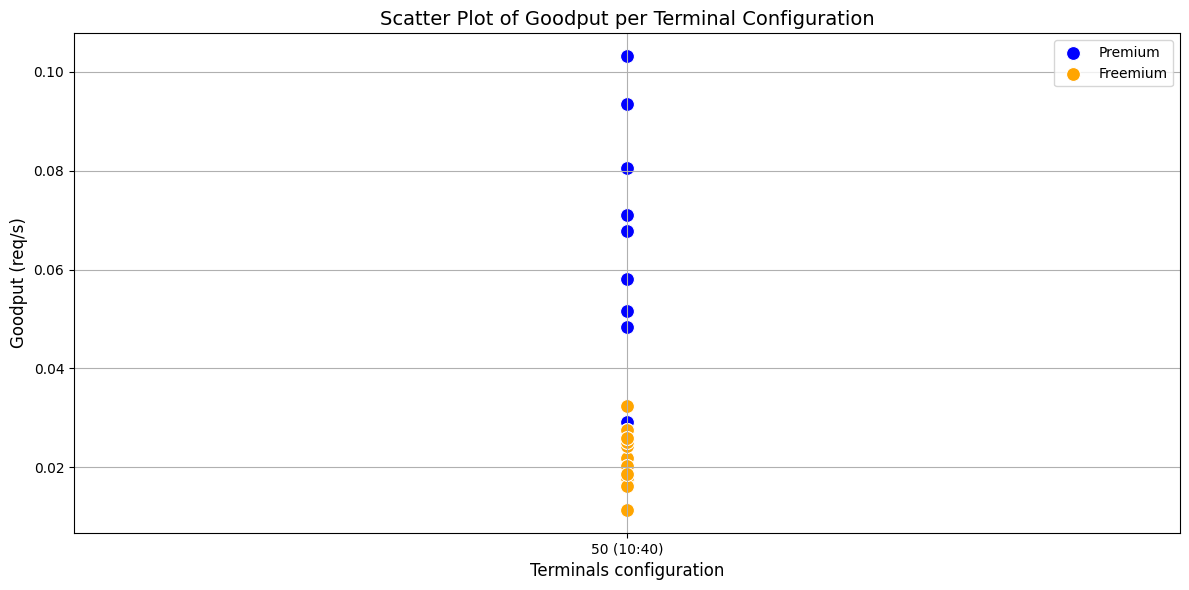

In [16]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Clients_Label', y='Premium Per Terminal Goodput', data=df, label='Premium', color='blue', s=100)
sns.scatterplot(x='Clients_Label', y='Freemium Per Terminal Goodput', data=df, label='Freemium', color='orange', s=100)
plt.xlabel('Terminals configuration', fontsize=12)
plt.ylabel('Goodput (req/s)', fontsize=12)
plt.title('Scatter Plot of Goodput per Terminal Configuration', fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

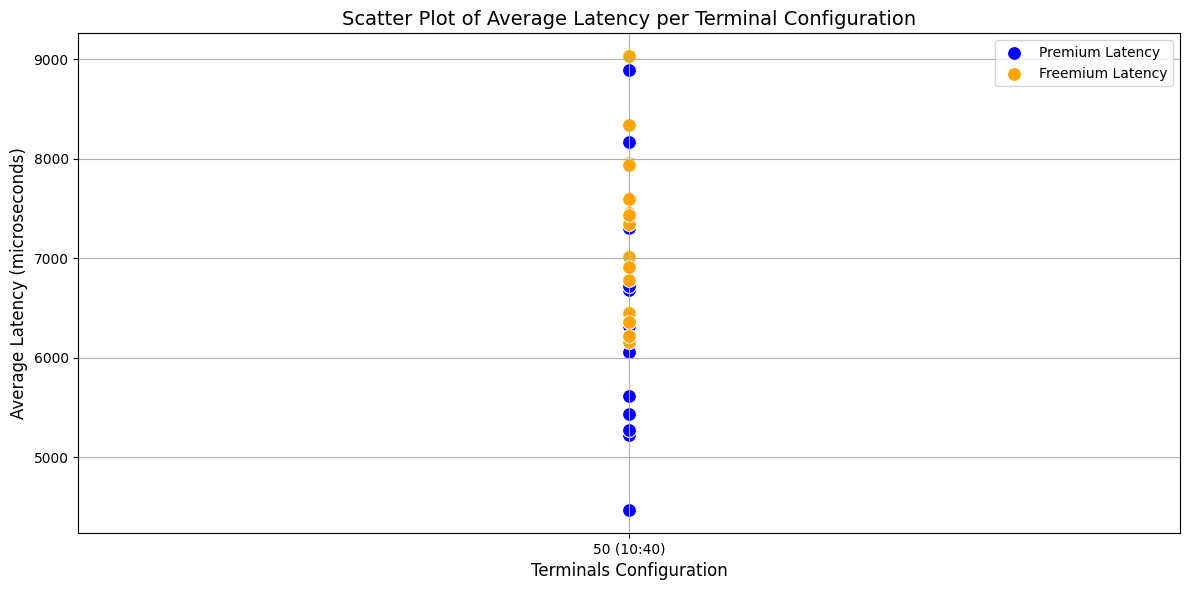

In [17]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Clients_Label', y='Premium Avg Latency', data=df, label='Premium Latency', color='blue', s=100)
sns.scatterplot(x='Clients_Label', y='Freemium Avg Latency', data=df, label='Freemium Latency', color='orange', s=100)
plt.xlabel('Terminals Configuration', fontsize=12)
plt.ylabel('Average Latency (microseconds)', fontsize=12)
plt.title('Scatter Plot of Average Latency per Terminal Configuration', fontsize=14)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

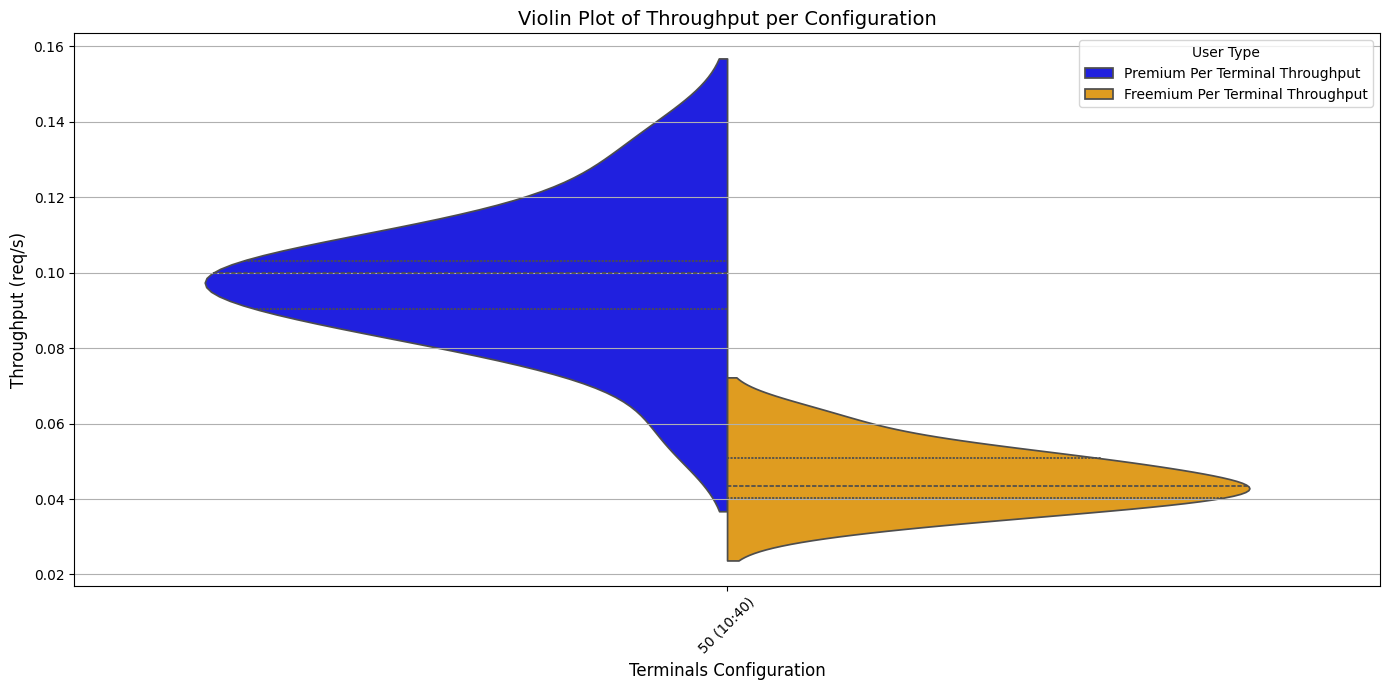

In [22]:
df_melted_throughput = pd.melt(df, 
                               id_vars=['Clients_Label'], 
                               value_vars=['Premium Per Terminal Throughput', 'Freemium Per Terminal Throughput'],
                               var_name='User_Type', 
                               value_name='PerTerminalTroughput')

df_melted_throughput['User_Type'] = df_melted_throughput['User_Type'].replace({
    'premium_Throughput': 'Premium',
    'freemium_Throughput': 'Freemium'
})

plt.figure(figsize=(14, 7))
sns.violinplot(x='Clients_Label', y='PerTerminalTroughput', hue='User_Type', data=df_melted_throughput, 
               split=True, inner='quartile', palette=['blue', 'orange'])

plt.xlabel('Terminals Configuration', fontsize=12)
plt.ylabel('Throughput (req/s)', fontsize=12)
plt.title('Violin Plot of Throughput per Configuration', fontsize=14)
plt.legend(title='User Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y')
plt.show()

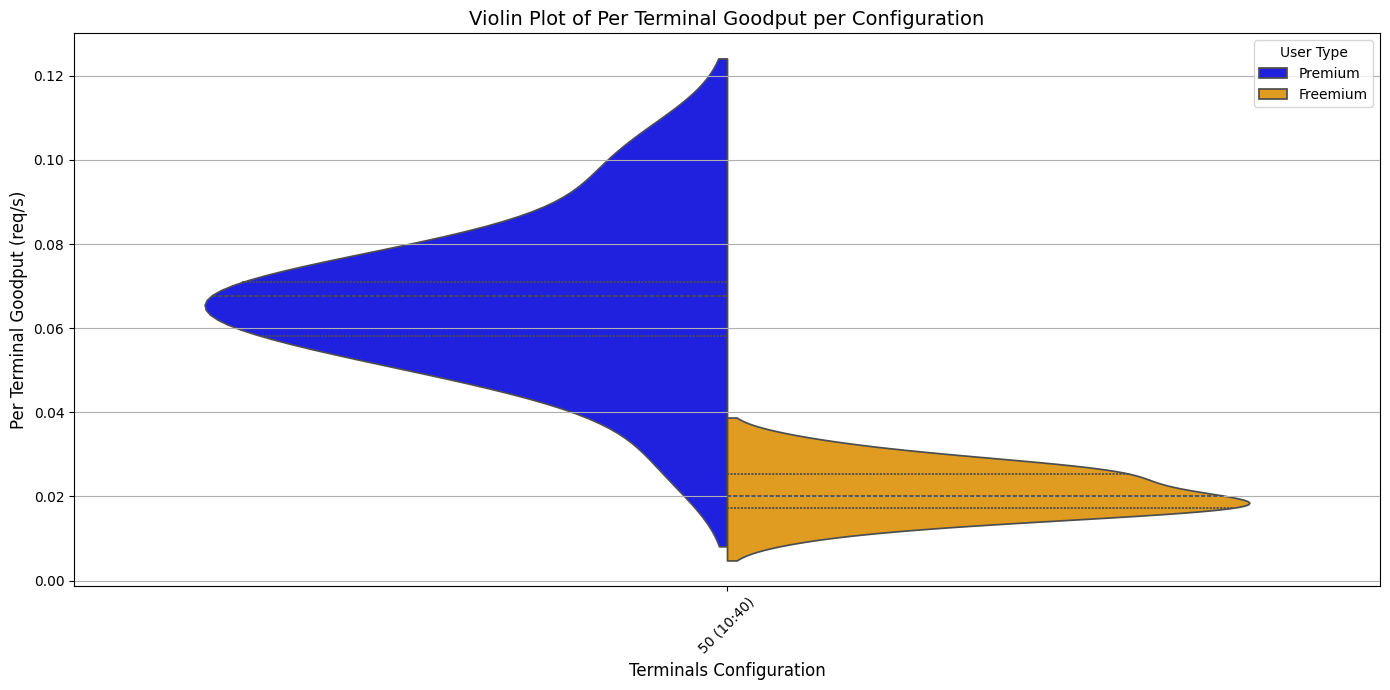

In [18]:
df_melted = pd.melt(df, 
                    id_vars=['Clients_Label'], 
                    value_vars=['premium_PerTerminalGoodput', 'freemium_PerTerminalGoodput'],
                    var_name='User_Type', 
                    value_name='PerTerminalGoodput')

df_melted['User_Type'] = df_melted['User_Type'].replace({
    'premium_PerTerminalGoodput': 'Premium',
    'freemium_PerTerminalGoodput': 'Freemium'
})

# Violin Plot
plt.figure(figsize=(14, 7))
sns.violinplot(x='Clients_Label', y='PerTerminalGoodput', hue='User_Type', data=df_melted, split=True, inner='quartile', palette=['blue', 'orange'])
plt.xlabel('Terminals Configuration', fontsize=12)
plt.ylabel('Per Terminal Goodput (req/s)', fontsize=12)
plt.title('Violin Plot of Per Terminal Goodput per Configuration', fontsize=14)
plt.legend(title='User Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y')
plt.show()

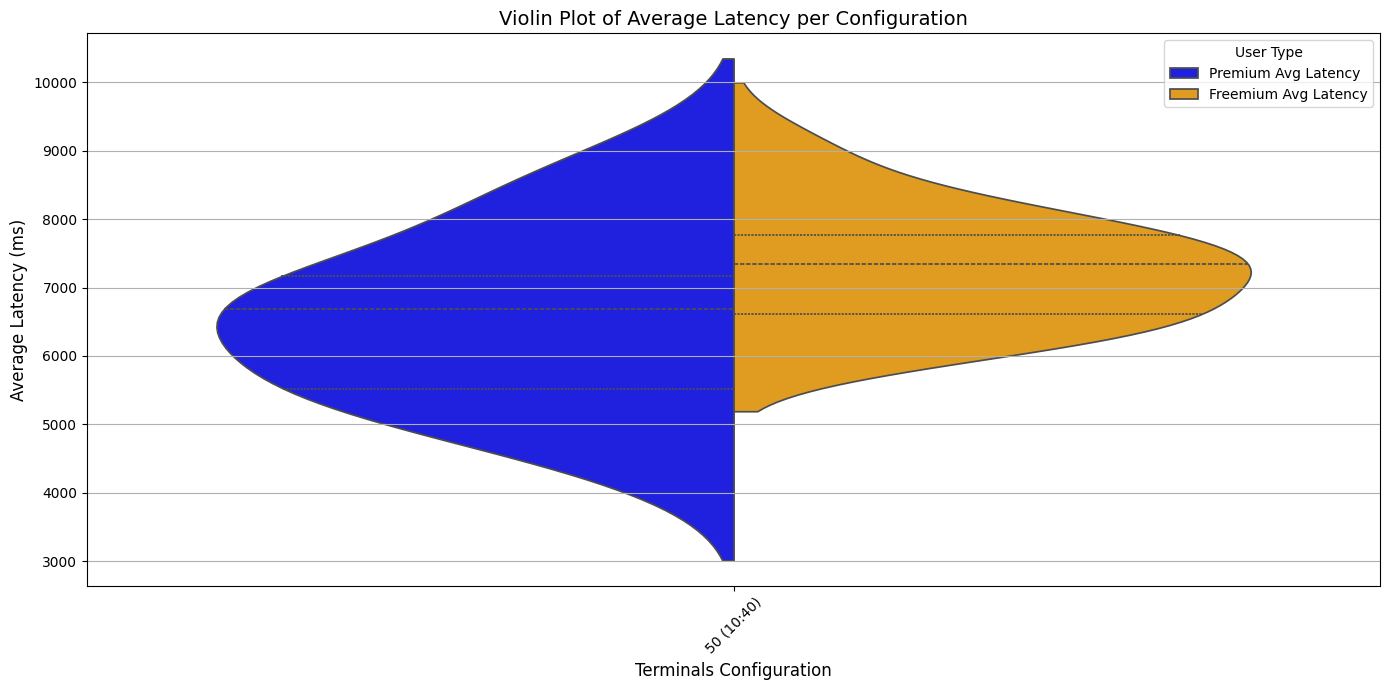

In [21]:
df_melted_latency = pd.melt(df, 
                            id_vars=['Clients_Label'], 
                            value_vars=['Premium Avg Latency', 'Freemium Avg Latency'],
                            var_name='User_Type', 
                            value_name='AverageLatency')

df_melted_latency['User_Type'] = df_melted_latency['User_Type'].replace({
    'premium_AverageLatency': 'Premium',
    'freemium_AverageLatency': 'Freemium'
})

plt.figure(figsize=(14, 7))
sns.violinplot(x='Clients_Label', y='AverageLatency', hue='User_Type', data=df_melted_latency, 
               split=True, inner='quartile', palette=['blue', 'orange'])

plt.xlabel('Terminals Configuration', fontsize=12)
plt.ylabel('Average Latency (ms)', fontsize=12)
plt.title('Violin Plot of Average Latency per Configuration', fontsize=14)
plt.legend(title='User Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(axis='y')
plt.show()
